# Chapter 3: Production Duality, Factor Demand, and Firm Optimization

This notebook reruns four worked examples from the chapter: a monopolist's output with a capacity ceiling, Shephard's lemma, the shutdown rule, and least-cost inputs under a labor minimum. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def isoquant(ax, y_target, x_min, x_max, kind="cobb_douglas", a=1 / 3, A=1.0, col="teal", text=None, n=300):
    """Isoquant of A L^a K^(1-a) = y_target (kind 'cobb_douglas') with L on x and K on y."""
    L = np.linspace(x_min, x_max, n)
    K = (y_target / (A * L ** a)) ** (1.0 / (1.0 - a))
    ax.plot(L, K, color=color(col), linewidth=2)
    if text:
        label(ax, L[-1], K[-1], text, col=col, dx=-4, dy=6, ha="right")
    return L, K


def isocost(ax, cost, w, r, col="ink", style="dashed", text=None, text_frac=0.15):
    """Isocost line w L + r K = cost."""
    ax.plot([0, cost / w], [cost / r, 0], color=color(col), linestyle=style, linewidth=1.5)
    if text:
        L = text_frac * cost / w
        label(ax, L, (cost - w * L) / r, text, col=col, dx=6, dy=4)


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def signed(value, digits=2, comma=True):
    """Number for use inside a written sum: negatives get parentheses, '(-5.00)'."""
    text = num(value, digits, comma)
    return f"({text})" if text.startswith("-") else text


def monopoly_quadratic(a, b, F, c1, c2, cap=None):
    """Monopoly with inverse demand P = a - b q and cost C = F + c1 q + c2 q^2, optional capacity.

    profit-maximization-condition: a = 120, b = 2, F = 200, c1 = 20, c2 = 1 gives
    MR = 120 - 4q, MC = 20 + 2q, q* = 50/3 = 16.67, price 86.67, revenue 1,444.44,
    cost 811.11, profit 633.33. With cap = 12: price 96, profit 568, MR - MC = 72 - 44 = 28.
    Returns q, price, revenue, cost, profit, mr, mc, gap (MR - MC at q), atc, binding, q_free.
    """
    q_free = (a - c1) / (2.0 * b + 2.0 * c2)
    binding = cap is not None and q_free > cap
    q = float(cap) if binding else q_free
    price = a - b * q
    revenue = price * q
    cost = F + c1 * q + c2 * q * q
    mr = a - 2.0 * b * q
    mc = c1 + 2.0 * c2 * q
    return {"q": q, "price": price, "revenue": revenue, "cost": cost, "profit": revenue - cost, "mr": mr,
            "mc": mc, "gap": mr - mc, "atc": cost / q, "binding": binding, "q_free": q_free}


def conditional_factor_demand(w, r, y):
    """Least-cost (L, K) for y = sqrt(L K): L = y sqrt(r/w), K = y sqrt(w/r).

    shephards-lemma: y = 100, w = 16, r = 4 gives (50, 200); w = 25 gives (40, 250).
    """
    return y * math.sqrt(r / w), y * math.sqrt(w / r)


def cobb_douglas_cost(w, r, y):
    """Cost function c(w, r, y) = 2 y sqrt(w r) for y = sqrt(L K). shephards-lemma: c(16, 4, 100) = 1,600."""
    return 2.0 * y * math.sqrt(w * r)


def shutdown_check(p, fixed, avoidable_open, opening=80.0, c1=10.0, c2=1.0):
    """Price-taking plant with VC(q) = opening + c1 q + c2 q^2 and a fixed commitment.

    shutdown-rule: fixed = 500, opening = 80 avoidable. AVC = 80/q + 10 + q is lowest at
    q = sqrt(80) = 8.94, so the shutdown price is 27.89. At p = 30: q = 10, revenue 300,
    avoidable cost 280, contribution 20, profit -480 against -500 closed. At p = 26: q = 8,
    revenue 208, avoidable cost 224, contribution -16, so close. If the opening cost is
    owed anyway (avoidable_open False), the avoidable cost at p = 26 is 144 and contribution 64.
    Returns q, revenue, avoidable_cost, contribution, operate, profit_open, profit_closed,
    profit, shutdown_price, q_min_avc.
    """
    q = max(0.0, (p - c1) / (2.0 * c2))
    revenue = p * q
    avoidable = (opening if avoidable_open else 0.0) + c1 * q + c2 * q * q
    contribution = revenue - avoidable
    sunk_opening = 0.0 if avoidable_open else opening
    profit_open = contribution - fixed - sunk_opening
    profit_closed = -fixed - sunk_opening
    operate = contribution > 0
    if avoidable_open:
        q_min = math.sqrt(opening / c2)
        shutdown_price = opening / q_min + c1 + c2 * q_min
    else:
        q_min = 0.0
        shutdown_price = c1
    return {"q": q, "revenue": revenue, "avoidable_cost": avoidable, "contribution": contribution,
            "operate": operate, "tie": contribution == 0, "profit_open": profit_open,
            "profit_closed": profit_closed, "profit": profit_open if operate else profit_closed,
            "shutdown_price": shutdown_price, "q_min_avc": q_min}


def cobb_douglas_cost_min(w, r, y, a=1.0 / 3.0, floor=None):
    """Least-cost inputs for y = L^a K^(1 - a), with an optional minimum on labor.

    cost-minimization-constrained-optimization: a = 1/3, y = 100, w = 20, r = 5 gives
    K = 8L, L = 25, K = 200, cost 1,500. At w = 45: K = 18L, L = 14.5597, K = 262.07
    (book prints 262.08 from the rounded L), cost 1,965.56. With floor = 40 at w = 20 the
    floor binds: L = 40, K = (100 / 40^(1/3))^(3/2) = 158.11, cost 1,590.57.
    Returns L, K, cost, ratio (K/L at the interior optimum), binding, and the interior values.
    """
    ratio = (1.0 - a) / a * w / r              # K / L from f_L / f_K = w / r
    L_free = y / ratio ** (1.0 - a)            # y = L^a (ratio L)^(1-a) = ratio^(1-a) L
    K_free = ratio * L_free
    binding = floor is not None and L_free < floor
    if binding:
        L = float(floor)
        K = (y / L ** a) ** (1.0 / (1.0 - a))
    else:
        L, K = L_free, K_free
    return {"L": L, "K": K, "cost": w * L + r * K, "ratio": ratio, "binding": binding, "L_free": L_free,
            "K_free": K_free, "cost_free": w * L_free + r * K_free}


plt.rcParams.update(HOUSE_RC)


production = SimpleNamespace(monopoly_quadratic=monopoly_quadratic, conditional_factor_demand=conditional_factor_demand, cobb_douglas_cost=cobb_douglas_cost, shutdown_check=shutdown_check, cobb_douglas_cost_min=cobb_douglas_cost_min)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'profit-maximization-condition': {'a': 120,
                                   'b': 2,
                                   'F': 200,
                                   'c1': 20,
                                   'c2': 1,
                                   'q': 16.67,
                                   'price': 86.67,
                                   'revenue': 1444.44,
                                   'cost': 811.11,
                                   'profit': 633.33,
                                   'cap': 12,
                                   'cap_price': 96,
                                   'cap_profit': 568,
                                   'gap': 28,
                                   'mr_cap': 72,
                                   'mc_cap': 44,
                                   'atc_cap': 48.67},
 'shephards-lemma': {'y': 100,
                     'w': 16,
                     'r': 4,
                     'L': 50,
                     'K': 200,
                     'cost': 1600,
                     'w2': 25,
                     'L2': 40,
                     'K2': 250,
                     'cost2': 2000,
                     'tangent_increase': 450,
                     'actual_increase': 400},
 'shutdown-rule': {'fixed': 500,
                   'opening': 80,
                   'q_min': 8.94,
                   'shutdown_price': 27.89,
                   'p': 30,
                   'q': 10,
                   'revenue': 300,
                   'avoidable': 280,
                   'contribution': 20,
                   'profit': -480,
                   'p2': 26,
                   'q2': 8,
                   'revenue2': 208,
                   'avoidable2': 224,
                   'loss2_open': -516,
                   'avoidable2_sunk': 144,
                   'contribution2_sunk': 64},
 'cost-minimization-constrained-optimization': {'y': 100,
                                                'w': 20,
                                                'r': 5,
                                                'L': 25,
                                                'K': 200,
                                                'cost': 1500,
                                                'w2': 45,
                                                'L2': 14.56,
                                                'K2_printed_as': 262.08,
                                                'K2_exact_2dp': 262.07,
                                                'cost2': 1965.56,
                                                'floor': 40},
 'constructed': {'profit-maximization-condition': {'a': [100, 140], 'cap': [16, 8]},
                 'shephards-lemma': {'w': [9, 36], 'r': [1, 9]},
                 'shutdown-rule': {'p': [24, 28]},
                 'cost-minimization-constrained-optimization': {'w': [5],
                                                                'floor_case': 'K and cost under '
                                                                              'the floor'}}}


def _is_whole(x):
    return abs(x - round(x)) < 1e-9


def _frac(x):
    """Exact fraction text for the thirds and ninths of this example: 50/3, 13,000/9; whole numbers plain."""
    if _is_whole(x):
        return num(x, 0)
    for d in (3, 9):
        n = x * d
        if abs(n - round(n)) < 1e-6:
            g = math.gcd(int(round(n)), d)
            return f"{int(round(n)) // g:,}/{d // g}"
    return num(x)


def profit_picture(a=120, cap="none"):
    cap_value = None if cap == "none" else float(cap)
    res = production.monopoly_quadratic(a, 2, 200, 20, 1, cap_value)
    q = res["q"]
    qs = np.linspace(0, 30, 200)
    fig, ax = new_figure()
    ax.plot(qs, a - 4 * qs, color=PALETTE["teal"], linewidth=2.2, label=f"MR = {a} - 4q")
    ax.plot(qs, 20 + 2 * qs, color=PALETTE["gold"], linewidth=2.2, label="MC = 20 + 2q")
    if cap_value is not None:
        vline(ax, cap_value, f"capacity {num(cap_value, 0)}", col="terracotta", ha="right", y_frac=0.12)
    if res["binding"]:
        ax.plot([q, q], [res["mc"], res["mr"]], color=PALETTE["terracotta"], linewidth=5, solid_capstyle="butt")
        label(ax, q, (res["mr"] + res["mc"]) / 2, f"MR - MC = {num(res['gap'])}", col="terracotta", dx=-10, dy=0,
              ha="right", va="center")
    mark(ax, q, res["mc"], f"q = {num(q)}", col="ink", dx=8, dy=-14, va="top")
    ax.set_xlim(0, 30)
    ax.set_ylim(0, 150)
    ax.legend(loc="upper right", frameon=False)
    ax.set_xlabel("Output q")
    ax.set_ylabel("Dollars per unit")
    metrics = {"Output": num(q), "Price": money(res["price"]), "Revenue": money(res["revenue"]),
               "Total cost": money(res["cost"]), "Profit": money(res["profit"]),
               "MR - MC at the chosen output": num(res["gap"])}
    exact = _is_whole(q)
    qs_, ps_ = _frac(q), _frac(res["price"])
    rev_eq = f"{ps_} x {qs_} = " + ("" if exact else f"{_frac(res['revenue'])} = ") + num(res["revenue"])
    cost_eq = (f"200 + 20 x {qs_} + ({qs_})^2 = " if not exact else f"200 + 20 x {qs_} + {qs_}^2 = ") \
        + ("" if exact else f"{_frac(res['cost'])} = ") + num(res["cost"])
    prof_eq = (f"{num(res['revenue'])} - {num(res['cost'])}" if exact
               else f"{_frac(res['revenue'])} - {_frac(res['cost'])} = {_frac(res['profit'])}") + f" = {num(res['profit'])}"
    if res["binding"]:
        head = (f"The unconstrained output {num(res['q_free'])} exceeds the capacity, so q = {num(q, 0)}. "
                f"MR = {a} - 4 x {num(q, 0)} = {num(res['mr'])} and MC = 20 + 2 x {num(q, 0)} = {num(res['mc'])}, a gap of "
                f"{num(res['gap'])}, the value of one more unit of capacity.")
    else:
        head = (f"{a} - 4q = 20 + 2q gives q = ({a} - 20) / 6 = {qs_}" + ("" if exact else f" = {num(q)}")
                + (f", inside the capacity of {num(cap_value, 0)}." if cap_value is not None else "."))
    interp = (f"{head} Price = {a} - 2 x {qs_} = {ps_}" + ("" if exact else f" = {num(res['price'])}")
              + f"; revenue = {rev_eq}; cost = {cost_eq}; profit = {prof_eq}.")
    steps = [f"Unconstrained: q = ({a} - 20) / 6 = " + (_frac(res["q_free"]) + " = " if not _is_whole(res["q_free"]) else "")
             + num(res["q_free"]),
             (f"Capacity {num(cap_value, 0)} binds, so q = {num(q, 0)}" if res["binding"] else "Capacity does not bind"),
             f"Price = {a} - 2 x {qs_} = " + ("" if exact else f"{ps_} = ") + num(res["price"]),
             f"Revenue = {rev_eq}",
             f"Cost = {cost_eq}",
             f"Profit = {prof_eq}"]
    alt = (f"Marginal revenue and marginal cost lines against output with demand intercept {a}. The chosen output is "
           f"{num(q)}" + (f", at the capacity wall where MR exceeds MC by {num(res['gap'])}." if res["binding"]
                          else ", where the two lines cross."))
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def shephard_picture(w=16, r=4):
    y, w0 = 100, 16
    L, K = production.conditional_factor_demand(w, r, y)
    cost = production.cobb_douglas_cost(w, r, y)
    L0, _ = production.conditional_factor_demand(w0, r, y)
    c0 = production.cobb_douglas_cost(w0, r, y)
    tangent = c0 + L0 * (w - w0)
    ws = np.linspace(4, 40, 200)
    fig, ax = new_figure()
    ax.plot(ws, [production.cobb_douglas_cost(x, r, y) for x in ws], color=PALETTE["navy"], linewidth=2.2,
            label=f"minimum cost c(w, {r}, 100)")
    ax.plot(ws, c0 + L0 * (ws - w0), color=PALETTE["gold"], linewidth=1.6, linestyle="dashed",
            label=f"tangent at w = 16, slope L = {num(L0)}")
    mark(ax, w, cost, col="navy")
    if w != w0:
        mark(ax, w, tangent, col="gold")
    ax.text(0.97, 0.05, f"at w = {w}: cost {num(cost)}, tangent {num(tangent)}", transform=ax.transAxes,
            ha="right", va="bottom", fontsize=10.5, color=PALETTE["ink"])
    top = max(production.cobb_douglas_cost(40, r, y), c0 + L0 * 24)
    ax.set_xlim(4, 40)
    ax.set_ylim(0, top * 1.15)
    ax.legend(loc="upper left", frameon=False)
    ax.set_xlabel("Wage w")
    ax.set_ylabel("Cost of 100 units")
    metrics = {"Labor L": num(L), "Machine services K": num(K), "Minimum cost": num(cost),
               "Tangent prediction from w = 16": num(tangent), "Tangent minus actual": num(tangent - cost)}
    interp = (f"L = 100 x sqrt({r} / {w}) = {num(L)} and K = 100 x sqrt({w} / {r}) = {num(K)}, so cost = 2 x 100 x "
              f"sqrt({w} x {r}) = {num(cost)}, which equals {w} x {num(L, 4)} + {r} x {num(K, 4)}. Holding labor at its w = 16 "
              f"level predicts {num(c0)} + {num(L0)} x ({w} - 16) = {num(tangent)}, "
              + ("exactly the cost at w = 16." if w == w0 else
                 f"{num(tangent - cost)} above the true cost, because the firm substitutes toward "
                 + ("machines as the wage rises." if w > w0 else "labor as the wage falls.")))
    steps = [f"L = 100 x sqrt({r} / {w}) = {num(L)}", f"K = 100 x sqrt({w} / {r}) = {num(K)}",
             f"Cost = 2 x 100 x sqrt({w * r}) = {num(cost)}",
             f"Tangent = {num(c0)} + {num(L0)} x {signed(w - w0, 0)} = {num(tangent)}",
             f"Tangent - actual = {num(tangent)} - {num(cost)} = {num(tangent - cost)}"]
    alt = (f"The minimum cost curve against the wage with machine price {r}, and its tangent at w = 16. At w = {w} "
           f"cost is {num(cost)} and the tangent gives {num(tangent)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def shutdown_picture(p=30, avoidable="yes"):
    av = avoidable == "yes"
    res = production.shutdown_check(p, 500, av)
    q = res["q"]
    qs = np.linspace(2, 16, 200)
    fig, ax = new_figure()
    avc = (80 / qs if av else 0) + 10 + qs
    ax.plot(qs, avc, color=PALETTE["navy"], linewidth=2.2, label="AVC (avoidable cost per unit)")
    ax.plot(qs, 10 + 2 * qs, color=PALETTE["gold"], linewidth=2.2, label="MC = 10 + 2q")
    hline(ax, p, f"price {p}", col="teal", style="solid", x_frac=0.03)
    if av:
        mark(ax, res["q_min_avc"], res["shutdown_price"], f"shutdown price {num(res['shutdown_price'])}",
             col="terracotta", dx=8, dy=-12, va="top")
    crowded = av and q < res["q_min_avc"] and res["q_min_avc"] - q < 1.5
    mark(ax, q, p, f"q = {num(q, 0)}", col="ink", dx=-8 if crowded else 8, dy=6, ha="right" if crowded else "left")
    ax.set_xlim(2, 16)
    ax.set_ylim(10, 50)
    ax.legend(loc="upper right", frameon=False)
    ax.set_xlabel("Monthly output q")
    ax.set_ylabel("Dollars per unit")
    verdict = "operate" if res["operate"] else "shut down"
    metrics = {"Output if open": num(q, 0), "Revenue": money(res["revenue"], 0), "Avoidable cost": money(res["avoidable_cost"], 0),
               "Contribution": money(res["contribution"], 0), "Profit if open": money(res["profit_open"], 0),
               "Profit if closed": money(res["profit_closed"], 0), "Decision": verdict}
    opening = "80 + " if av else ""
    interp = (f"Price {p} = 10 + 2q gives q = {num(q, 0)}. Revenue = {p} x {num(q, 0)} = {num(res['revenue'], 0)}; avoidable cost = "
              f"{opening}10 x {num(q, 0)} + {num(q, 0)} x {num(q, 0)} = {num(res['avoidable_cost'], 0)}; contribution = "
              f"{num(res['revenue'], 0)} - {num(res['avoidable_cost'], 0)} = {num(res['contribution'], 0)}. Open, profit is "
              f"{num(res['profit_open'], 0)}; closed, {num(res['profit_closed'], 0)}. The plant should {verdict}."
              + ("" if av else " The $80 opening payment is owed either way, so it cancels from the comparison."))
    steps = [f"q from {p} = 10 + 2q: q = {num(q, 0)}", f"Revenue = {p} x {num(q, 0)} = {num(res['revenue'], 0)}",
             f"Avoidable cost = {opening}{num(10 * q, 0)} + {num(q * q, 0)} = {num(res['avoidable_cost'], 0)}",
             f"Contribution = {num(res['revenue'], 0)} - {num(res['avoidable_cost'], 0)} = {num(res['contribution'], 0)}",
             f"Decision: {verdict}"]
    alt = (f"Average avoidable cost and marginal cost curves with a price line at {p}. At q = {num(q, 0)} the "
           f"contribution is {num(res['contribution'], 0)}, so the plant should {verdict}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def costmin_picture(w=20, floor="none"):
    r, y = 5, 100
    fl = None if floor == "none" else float(floor)
    res = production.cobb_douglas_cost_min(w, r, y, 1 / 3, fl)
    fig, ax = new_figure()
    isoquant(ax, y, 5, 90, a=1 / 3, col="teal")
    ax.lines[-1].set_label("isoquant: 100 units")
    isocost(ax, res["cost"], w, r, col="ink")
    ax.lines[-1].set_label(f"isocost {num(res['cost'])}")
    if fl is not None:
        vline(ax, fl, f"labor floor {num(fl, 0)}", col="terracotta", y_frac=0.12)
    mark(ax, res["L"], res["K"], f"({num(res['L'])}, {num(res['K'])})", col="ink", dx=8, dy=8)
    ax.set_xlim(0, 90)
    ax.set_ylim(0, 600)
    ax.legend(loc="upper right", frameon=False)
    ax.set_xlabel("Labor L")
    ax.set_ylabel("Capital services K")
    ratio = res["ratio"]
    metrics = {"Labor L": num(res["L"]), "Capital K": num(res["K"]), "Cost": money(res["cost"]),
               "Interior K/L": num(ratio), "Cost without the floor": money(res["cost_free"]),
               "Labor floor": ("binds" if res["binding"] else "does not bind") if fl is not None else "none"}
    base = (f"K/(2L) = {w}/{r} gives K = {num(ratio)}L, and 100 = L^(1/3) ({num(ratio)}L)^(2/3) gives L = 100 / "
            f"{num(ratio)}^(2/3) = {num(res['L_free'])}, K = {num(res['K_free'])}.")
    if res["binding"]:
        tail = (f" The floor forces L = {num(fl, 0)}, so K = (100 / {num(fl, 0)}^(1/3))^(3/2) = {num(res['K'])} and cost = "
                f"{w} x {num(fl, 0)} + {r} x {num(res['K'], 4)} = {num(res['cost'])}, up from {num(res['cost_free'])}.")
    else:
        tail = (f" Cost = {w} x {num(res['L'], 4)} + {r} x {num(res['K'], 4)} = {num(res['cost'])}"
                + (f"; the floor of {num(fl, 0)} does not bind." if fl is not None else "."))
    interp = base + tail
    steps = [f"K = (2 x {w} / {r}) L = {num(ratio)}L", f"L = 100 / {num(ratio)}^(2/3) = {num(res['L_free'])}",
             f"K = {num(ratio)} x {num(res['L_free'], 4)} = {num(res['K_free'])}"]
    if res["binding"]:
        steps += [f"Floor binds: L = {num(fl, 0)}, K = 1,000 / sqrt({num(fl, 0)}) = {num(res['K'])}"]
    steps += [f"Cost = {w} x {num(res['L'], 0 if res['binding'] else 4)} + {r} x "
              f"{num(res['K'], 4)} = {num(res['cost'])}"]
    alt = (f"Isoquant for 100 units with the isocost line touching it at L = {num(res['L'])}, K = {num(res['K'])}"
           + (", on the labor floor." if res["binding"] else "."))
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Profit maximization: MR equals MC, then a capacity ceiling

Inverse demand $P(q)=120-2q$ and cost $C(q)=200+20q+q^2$:

$$R(q)=120q-2q^2,\qquad MR(q)=120-4q,\qquad MC(q)=20+2q$$

$$120-4q=20+2q\quad\Longrightarrow\quad q^*=\frac{50}{3}\approx16.67$$

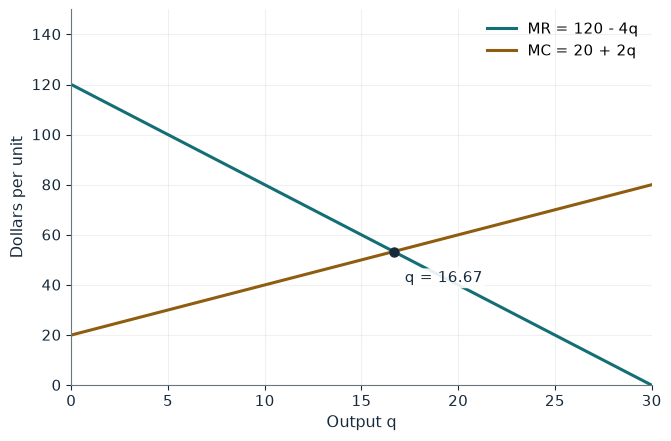

Output                        16.67
Price                         $86.67
Revenue                       $1,444.44
Total cost                    $811.11
Profit                        $633.33
MR - MC at the chosen output  0.00

Worked steps:
  1. Unconstrained: q = (120 - 20) / 6 = 50/3 = 16.67
  2. Capacity does not bind
  3. Price = 120 - 2 x 50/3 = 260/3 = 86.67
  4. Revenue = 260/3 x 50/3 = 13,000/9 = 1,444.44
  5. Cost = 200 + 20 x 50/3 + (50/3)^2 = 7,300/9 = 811.11
  6. Profit = 13,000/9 - 7,300/9 = 1,900/3 = 633.33

120 - 4q = 20 + 2q gives q = (120 - 20) / 6 = 50/3 = 16.67. Price = 120 - 2 x 50/3 = 260/3 = 86.67; revenue = 260/3 x 50/3 = 13,000/9 = 1,444.44; cost = 200 + 20 x 50/3 + (50/3)^2 = 7,300/9 = 811.11; profit = 13,000/9 - 7,300/9 = 1,900/3 = 633.33.


In [2]:
show(profit_picture(a=120, cap='none'))

Change one input, `cap`, and hold the others at the book's values:

In [3]:
sweep(profit_picture, 'cap', ['none', '16', '12', '8'], {'a': 120}, ['Output', 'Price', 'Profit', 'MR - MC at the chosen output'])

cap | Output | Price | Profit | MR - MC at the chosen output
none | 16.67 | $86.67 | $633.33 | 0.00
16 | 16.00 | $88.00 | $632.00 | 4.00
12 | 12.00 | $96.00 | $568.00 | 28.00
8 | 8.00 | $104.00 | $408.00 | 52.00


Unconstrained, q = 16.67 and profit is \$633.33. A ceiling of 12 gives price \$96, profit \$568 and $MR(12)-MC(12)=72-44=28$, the value of one more unit of capacity.

## 2. Shephard's lemma: cost function slopes are input demands

Technology $y=\sqrt{LK}$, $y=100$, $r=4$:

$$L^c=y\sqrt{\frac{r}{w}},\qquad K^c=y\sqrt{\frac{w}{r}},\qquad c(w,r,y)=2y\sqrt{wr}$$

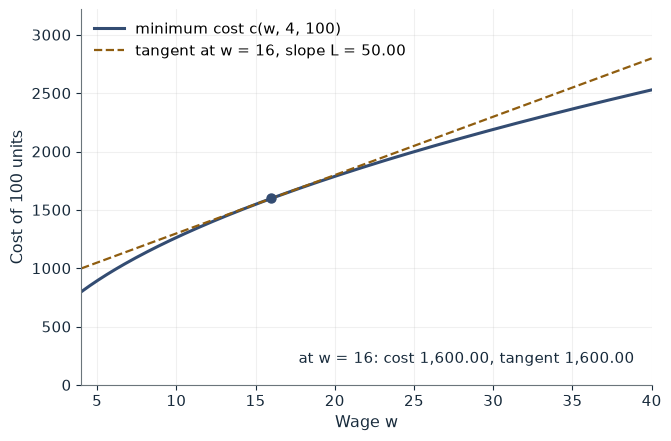

Labor L                         50.00
Machine services K              200.00
Minimum cost                    1,600.00
Tangent prediction from w = 16  1,600.00
Tangent minus actual            0.00

Worked steps:
  1. L = 100 x sqrt(4 / 16) = 50.00
  2. K = 100 x sqrt(16 / 4) = 200.00
  3. Cost = 2 x 100 x sqrt(64) = 1,600.00
  4. Tangent = 1,600.00 + 50.00 x 0 = 1,600.00
  5. Tangent - actual = 1,600.00 - 1,600.00 = 0.00

L = 100 x sqrt(4 / 16) = 50.00 and K = 100 x sqrt(16 / 4) = 200.00, so cost = 2 x 100 x sqrt(16 x 4) = 1,600.00, which equals 16 x 50.0000 + 4 x 200.0000. Holding labor at its w = 16 level predicts 1,600.00 + 50.00 x (16 - 16) = 1,600.00, exactly the cost at w = 16.


In [4]:
show(shephard_picture(w=16, r=4))

Change one input, `w`, and hold the others at the book's values:

In [5]:
sweep(shephard_picture, 'w', [9, 16, 25, 36], {'r': 4}, ['Labor L', 'Minimum cost', 'Tangent prediction from w = 16'])

w | Labor L | Minimum cost | Tangent prediction from w = 16
9 | 66.67 | 1,200.00 | 1,250.00
16 | 50.00 | 1,600.00 | 1,600.00
25 | 40.00 | 2,000.00 | 2,050.00
36 | 33.33 | 2,400.00 | 2,600.00


At w = 16 the firm uses 50 labor-hours and 200 machine-hours for \$1,600. Raising the wage to 25 raises cost by \$400, less than the \$450 the tangent predicts, because labor falls to 40.

## 3. Shutdown rule: operate at a loss or shut down?

Avoidable cost $VC(q)=80+10q+q^2$; \$500 is owed either way.

$$AVC(q)=\frac{80}{q}+10+q,\qquad MC(q)=10+2q$$

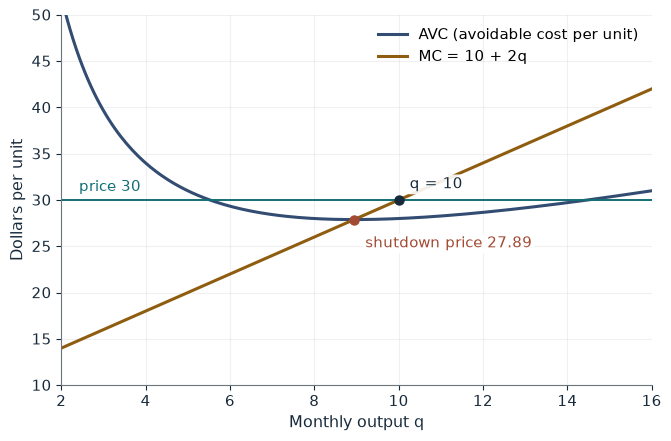

Output if open    10
Revenue           $300
Avoidable cost    $280
Contribution      $20
Profit if open    -$480
Profit if closed  -$500
Decision          operate

Worked steps:
  1. q from 30 = 10 + 2q: q = 10
  2. Revenue = 30 x 10 = 300
  3. Avoidable cost = 80 + 100 + 100 = 280
  4. Contribution = 300 - 280 = 20
  5. Decision: operate

Price 30 = 10 + 2q gives q = 10. Revenue = 30 x 10 = 300; avoidable cost = 80 + 10 x 10 + 10 x 10 = 280; contribution = 300 - 280 = 20. Open, profit is -480; closed, -500. The plant should operate.


In [6]:
show(shutdown_picture(p=30, avoidable='yes'))

Change one input, `p`, and hold the others at the book's values:

In [7]:
sweep(shutdown_picture, 'p', [24, 26, 28, 30], {'avoidable': 'yes'}, ['Output if open', 'Contribution', 'Decision'])

p | Output if open | Contribution | Decision
24 | 7 | -$31 | shut down
26 | 8 | -$16 | shut down
28 | 9 | $1 | operate
30 | 10 | $20 | operate


At \$30 the plant earns a \$20 contribution and loses \$480 instead of \$500, so it operates. At \$26 the contribution is -\$16 and it closes, unless the \$80 opening cost is owed anyway (`avoidable='no'`), in which case the contribution is \$64.

## 4. Cost minimization: least-cost inputs and a labor floor

Technology $y=L^{1/3}K^{2/3}$, target 100, $r=5$:

$$\frac{f_L}{f_K}=\frac{K}{2L}=\frac{w}{r}, \qquad 100=L^{1/3}(8L)^{2/3}=4L$$

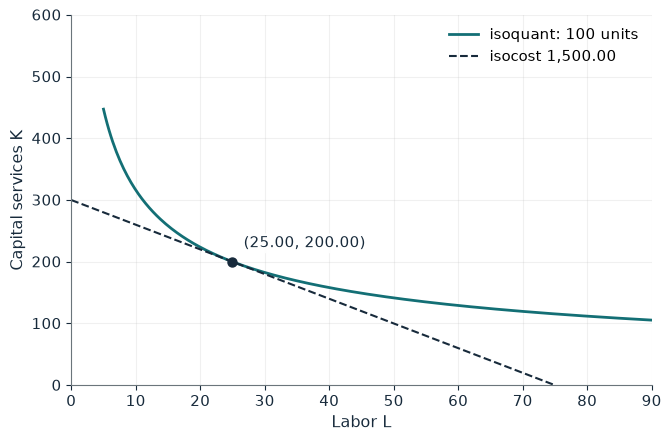

Labor L                 25.00
Capital K               200.00
Cost                    $1,500.00
Interior K/L            8.00
Cost without the floor  $1,500.00
Labor floor             none

Worked steps:
  1. K = (2 x 20 / 5) L = 8.00L
  2. L = 100 / 8.00^(2/3) = 25.00
  3. K = 8.00 x 25.0000 = 200.00
  4. Cost = 20 x 25.0000 + 5 x 200.0000 = 1,500.00

K/(2L) = 20/5 gives K = 8.00L, and 100 = L^(1/3) (8.00L)^(2/3) gives L = 100 / 8.00^(2/3) = 25.00, K = 200.00. Cost = 20 x 25.0000 + 5 x 200.0000 = 1,500.00.


In [8]:
show(costmin_picture(w=20, floor='none'))

Change one input, `w`, and hold the others at the book's values:

In [9]:
sweep(costmin_picture, 'w', [5, 20, 45], {'floor': '40'}, ['Labor L', 'Capital K', 'Cost', 'Labor floor'])

w | Labor L | Capital K | Cost | Labor floor
5 | 63.00 | 125.99 | $944.94 | does not bind
20 | 40.00 | 158.11 | $1,590.57 | binds
45 | 40.00 | 158.11 | $2,590.57 | binds


At w = 20 the firm uses L = 25 and K = 200 for \$1,500. At w = 45, L = 14.56 and K = 262.07 (exact value 18 x 14.5597) for \$1,965.56. A floor of 40 workers binds at w = 20 and w = 45.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

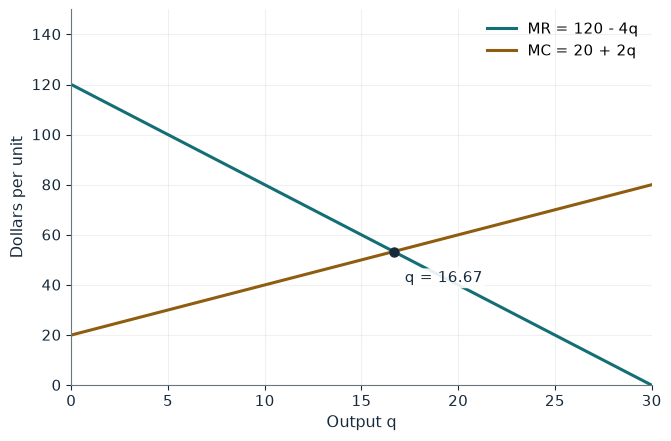

Output                        16.67
Price                         $86.67
Revenue                       $1,444.44
Total cost                    $811.11
Profit                        $633.33
MR - MC at the chosen output  0.00

Worked steps:
  1. Unconstrained: q = (120 - 20) / 6 = 50/3 = 16.67
  2. Capacity does not bind
  3. Price = 120 - 2 x 50/3 = 260/3 = 86.67
  4. Revenue = 260/3 x 50/3 = 13,000/9 = 1,444.44
  5. Cost = 200 + 20 x 50/3 + (50/3)^2 = 7,300/9 = 811.11
  6. Profit = 13,000/9 - 7,300/9 = 1,900/3 = 633.33

120 - 4q = 20 + 2q gives q = (120 - 20) / 6 = 50/3 = 16.67. Price = 120 - 2 x 50/3 = 260/3 = 86.67; revenue = 260/3 x 50/3 = 13,000/9 = 1,444.44; cost = 200 + 20 x 50/3 + (50/3)^2 = 7,300/9 = 811.11; profit = 13,000/9 - 7,300/9 = 1,900/3 = 633.33.


In [10]:
show(profit_picture(a=120, cap='none'))

## Practice

**1.** With demand intercept 140 and no cap, what output and profit?

<details><summary>Answer</summary>

140 - 4q = 20 + 2q gives q = 20, price 100, profit 2,000 - 1,000 = 1,000.

</details>

**2.** At price 28 with an avoidable opening cost, what is the contribution?

<details><summary>Answer</summary>

q = 9, revenue 252, avoidable cost 80 + 90 + 81 = 251, contribution +1: operate.

</details>

**3.** At w = 20 with the 40 labor floor, what capital and cost?

<details><summary>Answer</summary>

K = (100 / 40^(1/3))^(3/2) = 158.11; cost = 800 + 790.57 = 1,590.57.

</details>